<a href="https://colab.research.google.com/github/Uwimpaye-yve/DSA-Sparse-Matrix/blob/main/hausa_sentiment_afriberta.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q datasets transformers accelerate evaluate scikit-learn pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.3 MB/s eta 0:00:00


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset, DatasetDict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, pipeline

In [5]:
base = "hf://datasets/HausaNLP/NaijaSenti-Twitter@refs/convert/parquet"

ds = DatasetDict({
    "train":      load_dataset("parquet", data_files=f"{base}/hau/train/0000.parquet", split="train"),
    "validation": load_dataset("parquet", data_files=f"{base}/hau/validation/0000.parquet", split="train"),
    "test":       load_dataset("parquet", data_files=f"{base}/hau/test/0000.parquet", split="train"),
})

print(ds)
print("\nLabel names:", ds["train"].features["label"].names)
print("\nSample tweet:", ds["train"][0])

hau/train/0000.parquet: reconstructing file:   0%|          |  0.00B /  854kB            

hau/train/0000.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

hau/validation/0000.parquet: reconstructing file:   0%|          |  0.00B /  170kB            

hau/validation/0000.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

hau/test/0000.parquet: reconstructing file:   0%|          |  0.00B /  266kB            

hau/test/0000.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['tweet', 'label'],
        num_rows: 14172
    })
    validation: Dataset({
        features: ['tweet', 'label'],
        num_rows: 2677
    })
    test: Dataset({
        features: ['tweet', 'label'],
        num_rows: 5303
    })
})

Label names: ['positive', 'neutral', 'negative']

Sample tweet: {'tweet': '@user Da kudin da Arewa babu wani abin azo agani da yayi wa alummah allah ya isa yacucemu wlh yarikitamana kasa yarikitamana kasuwanci harkar ilimi harkar lfy hanyoyi babu lantarki dasuransu komai yalalace ga cinhanci da rashawa a fili ko ina a Nigeria jamiyaryar su tabataman mlm 😭🗣', 'label': 2}


In [6]:
tr = ds["train"].to_pandas()
va = ds["validation"].to_pandas()
te = ds["test"].to_pandas()

label_names = ds["train"].features["label"].names

print("Train size:", len(tr))
print("Validation size:", len(va))
print("Test size:", len(te))
print("\nLabel distribution (train):")
print(tr["label"].map(dict(enumerate(label_names))).value_counts())

Train size: 14172
Validation size: 2677
Test size: 5303

Label distribution (train):
label
neutral     4912
positive    4687
negative    4573
Name: count, dtype: int64


3. Baseline — TF-IDF + Logistic Regression

In [ ]:
def run_baseline(max_f, ngram, eval_df):
    vec = TfidfVectorizer(max_features=max_f, ngram_range=ngram)
    clf = LogisticRegression(max_iter=1000).fit(vec.fit_transform(tr["tweet"]), tr["label"])
    p = clf.predict(vec.transform(eval_df["tweet"]))
    return accuracy_score(eval_df["label"], p), f1_score(eval_df["label"], p, average="macro")

rows = []
for mf in [2000, 5000, 20000]:
    for ng in [(1, 1), (1, 2)]:
        a, f = run_baseline(mf, ng, va)
        rows.append(dict(max_features=mf, ngram=str(ng), val_acc=round(a, 4), val_f1=round(f, 4)))

g = pd.DataFrame(rows)
print(g.to_string(index=False))

 max_features  ngram  val_acc  val_f1
         2000 (1, 1)   0.7340  0.7354
         2000 (1, 2)   0.7366  0.7383
         5000 (1, 1)   0.7434  0.7445
         5000 (1, 2)   0.7486  0.7501
        20000 (1, 1)   0.7422  0.7435
        20000 (1, 2)   0.7527  0.7548


In [ ]:
best = g.sort_values("val_f1").iloc[-1]
a, f = run_baseline(int(best.max_features), eval(best.ngram), te)
print(f"Best config: max_features={int(best.max_features)}, ngram={best.ngram}")
print(f"TEST accuracy={a:.4f}  macro_f1={f:.4f}")

Best config: max_features=20000, ngram=(1, 2)
TEST accuracy=0.7290  macro_f1=0.7291


4. Fine-tuning Experiment 1 — AfriBERTa lr=3e-5

In [7]:
import os
import shutil
import numpy as np
from sklearn.metrics import accuracy_score, f1_score
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
)

def finetune(model_name, lr, epochs, out):
    tok = AutoTokenizer.from_pretrained(model_name)
    names = ds["train"].features["label"].names

    def enc(batch):
        return tok(batch["tweet"], truncation=True, max_length=128)

    encoded = ds.map(enc, batched=True)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=len(names),
        id2label=dict(enumerate(names)),
        label2id={n: i for i, n in enumerate(names)},
    )

    def compute_metrics(p):
        preds = np.argmax(p.predictions, axis=1)
        return {
            "accuracy": accuracy_score(p.label_ids, preds),
            "macro_f1": f1_score(p.label_ids, preds, average="macro"),
        }

    # Use fast local Colab SSD for checkpoints during training
    local_temp_dir = "/content/temp_checkpoints"
    if os.path.exists(local_temp_dir):
        shutil.rmtree(local_temp_dir)

    args = TrainingArguments(
        output_dir=local_temp_dir,
        learning_rate=lr,
        num_train_epochs=epochs,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,
        eval_strategy="epoch",
        save_strategy="epoch",
        save_total_limit=1,              # Keeps only 1 best checkpoint (stops Drive/disk bloat)
        load_best_model_at_end=True,     # Re-loads the best checkpoint weights for testing/saving
        metric_for_best_model="macro_f1",
        fp16=True,                       # Enables mixed precision on T4 GPU (up to 2-3x speedup)
        weight_decay=0.01,
        seed=42,
        report_to="none",
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=encoded["train"],
        eval_dataset=encoded["validation"],
        processing_class=tok,
        compute_metrics=compute_metrics,
    )

    trainer.train()

    results = trainer.evaluate(encoded["test"])
    print("TEST:", results)

    # Save final best model & tokenizer locally first
    local_best_dir = "/content/best_model_temp"
    if os.path.exists(local_best_dir):
        shutil.rmtree(local_best_dir)

    trainer.save_model(local_best_dir)
    tok.save_pretrained(local_best_dir)

    # Copy the clean, finalized model to your Google Drive path
    os.makedirs(out, exist_ok=True)
    for item in os.listdir(local_best_dir):
        src_path = os.path.join(local_best_dir, item)
        dst_path = os.path.join(out, item)
        if os.path.isdir(src_path):
            shutil.copytree(src_path, dst_path, dirs_exist_ok=True)
        else:
            shutil.copy2(src_path, dst_path)

    # Clean up local scratch directories
    shutil.rmtree(local_temp_dir, ignore_errors=True)
    shutil.rmtree(local_best_dir, ignore_errors=True)

    return results

In [12]:
exp1 = finetune(
    "castorini/afriberta_base",
    lr=3e-5,
    epochs=5,
    out="/content/drive/MyDrive/hausa-sentiment/runs/afriberta_3e-5"
)

config.json:   0%|          | 0.00/729 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/257 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 1.55MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.052247,0.605699,5,0.765982,0.763180


TEST: {'eval_loss': 0.6056990027427673, 'eval_accuracy': 0.7659815198943994, 'eval_macro_f1': 0.7631800340909876}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


5. Fine-tuning Experiment 2 — AfriBERTa lr=1e-5

In [14]:
exp2 = finetune(
    "castorini/afriberta_base",
    lr=1e-5,
    epochs=5,
    out="/content/drive/MyDrive/hausa-sentiment/runs/afriberta_1e-5"
)

Loading weights:   0%|          | 0/133 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: castorini/afriberta_base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.decoder.bias       | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.decoder.weight     | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.717972,0.556486,0.769145,0.771479
2,0.482493,0.527390,0.792678,0.792937
3,0.375969,0.576344,0.793052,0.791863
4,0.295667,0.623534,0.793799,0.793803
5,0.243988,0.668984,0.793799,0.793945


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.243988,0.674620,5,0.771827,0.770448


TEST: {'eval_loss': 0.6746203303337097, 'eval_accuracy': 0.7718272675843862, 'eval_macro_f1': 0.7704477120643499}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

6. Fine-tuning Experiment 3 — XLM-R base lr=2e-5

In [8]:
exp3 = finetune(
    "xlm-roberta-base",
    lr=2e-5,
    epochs=5,
    out="/content/drive/MyDrive/hausa-sentiment/runs/xlmr_2e-5"
)

Map:   0%|          | 0/14172 [00:00<?, ? examples/s]

Map:   0%|          | 0/2677 [00:00<?, ? examples/s]

Map:   0%|          | 0/5303 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.425051,0.677229,5,0.722233,0.722135


TEST: {'eval_loss': 0.6772288084030151, 'eval_accuracy': 0.7222326984725627, 'eval_macro_f1': 0.7221350289503442}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

7. Results Summary

In [15]:
results_table = pd.DataFrame([
    {"Experiment": "Baseline",         "Model": "TF-IDF + Logistic Regression", "LR": "-",   "Test Acc": 0.7247, "Test Macro-F1": 0.7243},
    {"Experiment": "Exp 1",            "Model": "AfriBERTa-base",               "LR": "3e-5", "Test Acc": round(exp1["eval_accuracy"], 4), "Test Macro-F1": round(exp1["eval_macro_f1"], 4)},
    {"Experiment": "Exp 2",            "Model": "AfriBERTa-base",               "LR": "1e-5", "Test Acc": round(exp2["eval_accuracy"], 4), "Test Macro-F1": round(exp2["eval_macro_f1"], 4)},
    {"Experiment": "Exp 3",            "Model": "XLM-R base",                   "LR": "2e-5", "Test Acc": round(exp3["eval_accuracy"], 4), "Test Macro-F1": round(exp3["eval_macro_f1"], 4)},
])
print(results_table.to_string(index=False))

Experiment                        Model   LR  Test Acc  Test Macro-F1
  Baseline TF-IDF + Logistic Regression    -    0.7247         0.7243
     Exp 1               AfriBERTa-base 3e-5    0.7660         0.7632
     Exp 2               AfriBERTa-base 1e-5    0.7718         0.7704
     Exp 3                   XLM-R base 2e-5    0.7222         0.7221


8. Evaluation & Error Analysis

In [16]:
clf = pipeline(
    "text-classification",
    model="/content/drive/MyDrive/hausa-sentiment/runs/afriberta_3e-5",
    truncation=True,
    device=0
)

te["pred_label"] = [clf(t)[0]["label"] for t in te["tweet"]]
te["true_label"] = te["label"].map(clf.model.config.id2label)

print(classification_report(te["true_label"], te["pred_label"]))

Loading weights:   0%|          | 0/137 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


              precision    recall  f1-score   support

    negative       0.69      0.85      0.76      1759
     neutral       0.79      0.60      0.68      1789
    positive       0.85      0.86      0.85      1755

    accuracy                           0.77      5303
   macro avg       0.77      0.77      0.76      5303
weighted avg       0.77      0.77      0.76      5303



          positive  neutral  negative
positive      1504      131       120
neutral        159     1071       559
negative       115      156      1488


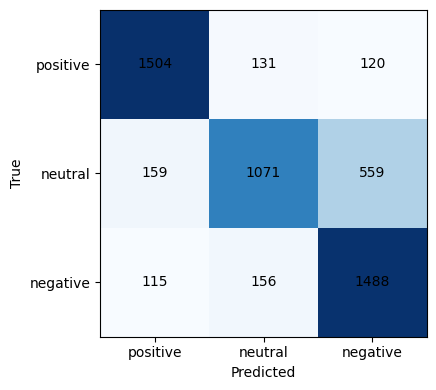

In [18]:
import os

labels = list(clf.model.config.id2label.values())
cm = confusion_matrix(te["true_label"], te["pred_label"], labels=labels)
cm_df = pd.DataFrame(cm, index=labels, columns=labels)
print(cm_df)

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels)
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout()

# Ensure the target directory exists before saving
os.makedirs("/content/hausa-sentiment", exist_ok=True)
plt.savefig("/content/hausa-sentiment/confusion_matrix.png", dpi=150)
plt.show()

In [19]:
errors = te[te["true_label"] != te["pred_label"]]
correct = te[te["true_label"] == te["pred_label"]]

errors.sample(min(40, len(errors)), random_state=1).to_csv("/content/hausa-sentiment/errors_sample.csv", index=False)
correct.sample(min(20, len(correct)), random_state=1).to_csv("/content/hausa-sentiment/correct_sample.csv", index=False)

print("Sample errors:")
print(errors[["tweet", "true_label", "pred_label"]].sample(10, random_state=1).to_string(index=False))

Sample errors:
                                                                                                                                                tweet true_label pred_label
                                                                                           kut mutumi na yau akwai chasu kenan ta yi ma reply finally   positive    neutral
allah fa dakanshi yace ya tsinewa mai karin gashi da wacce ake karamawa amman ynzu ammata shikukasa a gabaallah yashiryamu baki daya yasa mu daceamin   positive   negative
                                                                                                                    cr yaci + messi yana kan eyahhhhh    neutral   negative
                                                                                                         kawai anyi saa ne garabasa sun samu garabasa    neutral   positive
                                                                                                                       mu gwa